In [24]:
# Module 5 Lab 2 – Textbook Problems 5.2 and 5.3

## Problem 5.2: Weight Statistics and Histogram

# In this problem, I will analyze the weights of 20 people using Python.

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [26]:
weights = [
    164, 158, 172, 153, 144,
    156, 189, 163, 134, 159,
    143, 176, 177, 162, 141,
    151, 182, 185, 171, 152
]

print("Number of people:", len(weights))
print("Weights:", weights)

Number of people: 20
Weights: [164, 158, 172, 153, 144, 156, 189, 163, 134, 159, 143, 176, 177, 162, 141, 151, 182, 185, 171, 152]


In [27]:
mean_weight = np.mean(weights)
median_weight = np.median(weights)
std_weight = np.std(weights, ddof=1)

print(f"Mean Weight: {mean_weight:.2f} pounds")
print(f"Median Weight: {median_weight:.2f} pounds")
print(f"Standard Deviation: {std_weight:.2f} pounds")

Mean Weight: 161.60 pounds
Median Weight: 160.50 pounds
Standard Deviation: 15.45 pounds


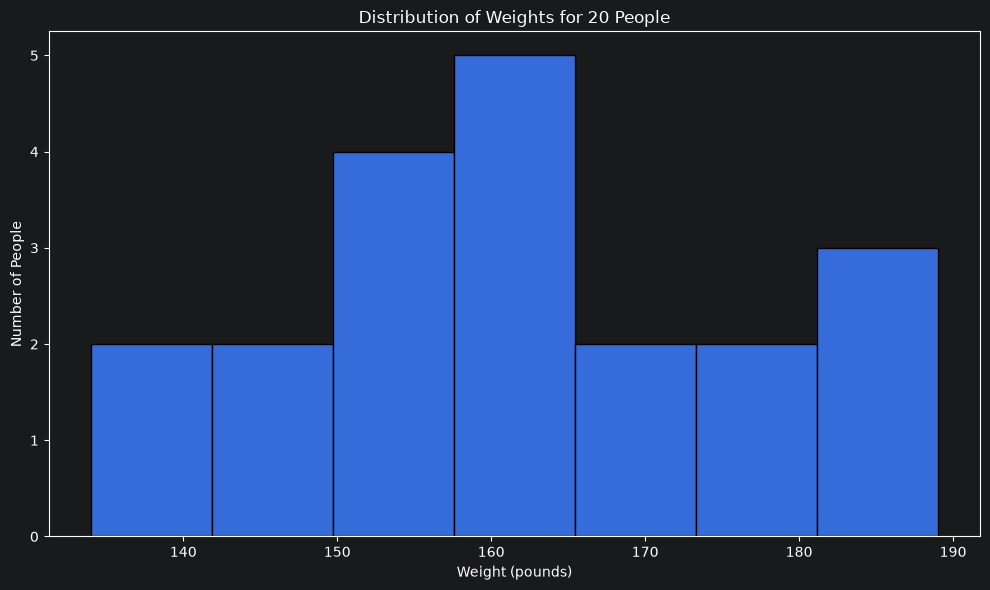

In [28]:
plt.figure(figsize=(10, 6))

plt.hist(weights, bins=7, edgecolor="black")

plt.title("Distribution of Weights for 20 People")
plt.xlabel("Weight (pounds)")
plt.ylabel("Number of People")

plt.tight_layout()
plt.show()

In [30]:
## Problem 5.2 Conclusion

# After analyzing the weights of 20 people, I found that the mean weight was 161.60 pounds and the median was 160.50 pounds. .

In [31]:
cust = pd.read_csv("custdata.tsv", sep="\t")

print("First five rows:")
print(cust.head())

print("\nColumn names:")
print(cust.columns.tolist())

print("\nDataset shape:")
print(cust.shape)

First five rows:
   custid sex is.employed  income   marital.stat  health.ins  \
0    2068   F         NaN   11300        Married        True   
1    2073   F         NaN       0        Married        True   
2    2848   M        True    4500  Never Married       False   
3    5641   M        True   20000  Never Married       False   
4    6369   F        True   12000  Never Married        True   

               housing.type recent.move  num.vehicles   age state.of.res  
0  Homeowner free and clear       False           2.0  49.0     Michigan  
1                    Rented        True           3.0  40.0      Florida  
2                    Rented        True           3.0  22.0      Georgia  
3     Occupied with no rent       False           0.0  22.0   New Mexico  
4                    Rented        True           1.0  31.0      Florida  

Column names:
['custid', 'sex', 'is.employed', 'income', 'marital.stat', 'health.ins', 'housing.type', 'recent.move', 'num.vehicles', 'age', 'state

In [32]:
housing_columns = [
    col for col in cust.columns
    if "hous" in col.lower()
]

print("Housing columns:", housing_columns)

housing_col = housing_columns[0]

housing = cust[housing_col].astype("string").str.strip()

housing = housing.replace(
    ["NA", "N/A", "", "None", "nan", "NULL"],
    pd.NA
)

total_rows = len(housing)
clean_housing = housing.dropna()
excluded_rows = total_rows - len(clean_housing)

print("Total rows:", total_rows)
print("Excluded rows:", excluded_rows)
print("Valid rows:", len(clean_housing))

Housing columns: ['housing.type']
Total rows: 1000
Excluded rows: 56
Valid rows: 944


In [33]:
housing_counts = clean_housing.value_counts()

housing_counts = housing_counts.sort_values(
    ascending=False
)

print("Housing Type Counts:")
print(housing_counts)

Housing Type Counts:
housing.type
Homeowner with mortgage/loan    412
Rented                          364
Homeowner free and clear        157
Occupied with no rent            11
Name: count, dtype: Int64


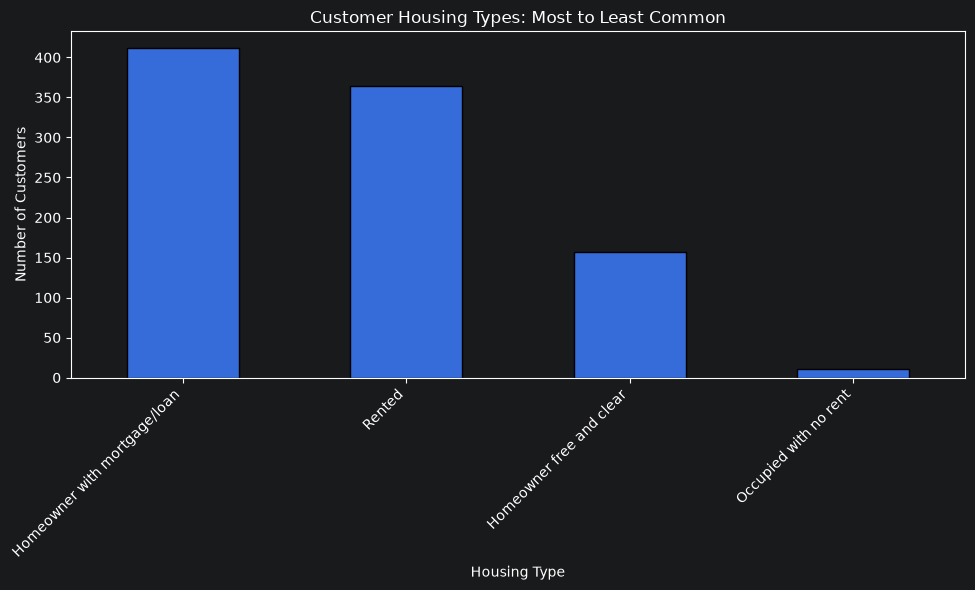

In [34]:
plt.figure(figsize=(10, 6))

housing_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Housing Types: Most to Least Common")
plt.xlabel("Housing Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [35]:
print(
    f"I excluded {excluded_rows} rows with "
    "missing or NA housing values before "
    "creating the bar chart."
)

I excluded 56 rows with missing or NA housing values before creating the bar chart.


In [36]:
# Problem 5.3 Conclusion

# I used Python for customer housing data. Before creating the bar chart, I checked the housing column for missing values and removed those entries. I then counted the customers in each housing category and sorted the results from highest to lowest.
